# Batching Tutorial

This notebook works through a TCTrack workflow using the batching utility to run the
[Tempest Extremes](https://tctrack.readthedocs.io/en/latest/tracking-algorithms/tempest_extremes.html)
tracker over the ERA5 reanalysis example data in batches, rather than all in
one go.

Batching splits the time range into a series of batches, running the tracker
over each in turn. This is useful for long datasets, where processing the data
all at once may use too much memory or disk space, or when the data for each
period needs to be retrieved separately.

We start by installing the tracker, then obtain and preprocess the example data,
run the tracking in batches, and finally visualise the resulting tracks.

## Setup

This notebook assumes that you have already run the Tempest Extremes notebook to install the
tracking algorithm software and retrieve the data. In which case, we only need to update the `PATH`.

In [1]:
import os

os.environ["PATH"] = f"{os.getcwd()}/tempestextremes/build/bin:{os.environ['PATH']}"

## Batching Function

The full documentation for the batching function can be found
[here](https://tctrack.readthedocs.io/en/latest/api/utils_api.html#tctrack.utils.batching).

For each batch period it will select the data for the appropriate time period and save it to a `batch_[i]/` directory.
Any preprocessing is then performed before running the tracker (using `run_tracker`).
After the trajectories have been found for all batches it will combine them into a single file.

Briefly, the required input arguments are:
- A tracker object.
- A list of input files.
- An interval for each batch (`"month"`, `"year"`, or a `cf.TimeDuration` object).
- The start and end dates in `"YYYY-MM-DD"`.

And the additional, optional arguments are:
- A list of preprocessing functions to perform on the input data.
- A function to manually retrieve data for each batch.
- A list of input files to pass to the tracker (after preprocessing).
- Additional configuration options.

For this tutorial we will use the seven-day data with a batch interval of four days.
i.e. two batch periods, the first is the full four days, the second is the remaining three days.
Typically, much longer batch intervals would be used.

First, we need to create the tracker. We will use the default parameter set.

In [2]:
import tctrack.tempest_extremes as te

detect_params, stitch_params = te.parameter_set("default", nc_names={"z": "z"})
tracker = te.TETracker(detect_params, stitch_params, verbosity=0)

#### Input files

Now we can specify the list of input files.

Only the (non-surface) geopotential data is used directly without any preprocessing, so can be copied to the batch directory unchanged.

For the other files we can avoid unnecessarily saving them to the batch directory and instead keep them in memory by providing a dictionary  with a `"store"` key.
The `"store"` values will be used to refer to the variables during the preprocessing. 

Finally, the surface geopotential (used to find orography) is not time-varying and should not be subspaced to the batch time periods.
To do this we use `"time_varying" = False`.

In [3]:
input_files = [
    "data/era5_z.nc",
    ("data/era5_sfc.nc", {"store": ["msl", "u10", "v10"]}),
    ("data/era5_sfc_z.nc", {"store": "z", "time_varying": False}),
]

#### Preprocessing

For the preprocessing we will provide a list of functions to apply during each batch.
Refer to the Tempest Extremes tutorial for details about why each function is applied.

Arguments are provided to each function using `functools.partial`.
As can be seen for each function below, the first argument can use use the fields stored in memory by using a key or list of keys.
Also, string arguments can refer to the batch directory or batch iteration by using  `%BATCH%` or `%ITER%`.

There are several steps to get the surface altitude from the geopotential (`"z"`), so we want to keep the results in memory.
To do this we use a 2-tuple where the second value is the key for storing the outputs.
Here it keeps using `"z"`, overwriting the previous values.

Here the [preprocessing helper
functions](https://tctrack.readthedocs.io/en/latest/api/preprocessing_api.html)
are used, but other functions can also be used.
To be compatible with the with loading / storing the fields in memory these must accept as the first argument / return a `cf.Field` object (or a list of them).

In [4]:
from functools import partial

import cf

from tctrack.preprocessing import (
    calculate_wind_speed,
    multiply_field,
    set_netcdf_info,
    squeeze_field,
)

GRAVITY = 9.80665  # Standard gravitational acceleration [m s-2]

preprocessing = [
    partial(cf.write, "msl", "%BATCH%/msl.nc"),
    partial(
        calculate_wind_speed,
        ["u10", "v10"],
        nc_name="si10",
        output_file="%BATCH%/si10.nc",
    ),
    (partial(squeeze_field, "z"), "z"),
    (partial(multiply_field, "z", 1 / GRAVITY), "z"),
    partial(
        set_netcdf_info,
        "z",
        nc_name="orog",
        properties={
            "standard_name": "surface_altitude",
            "long_name": "Surface Altitude",
            "units": "m",
        },
        output_file="%BATCH%/orog.nc",
    ),
]

#### Batching config

We can use a dictionary to configure the behaviour of the batching function.

The default config values are used here, so it is not strictly necessary.
However, it is included for clarity.

One option is to add a buffer period to prevent tracks from being cut off at the end of the batch period.
Ideally this should be longer than most tropical cyclone tracks (so >= 10 days).
If this is used, a short start buffer period prevents duplicate tracks
(any tracks starting in this period are removed).

No buffer period is used here since the period is already so short.

In [5]:
from datetime import timedelta

config = {
    "output_dir": "tctrack_outputs",  # Where to save outputs
    "combine_outputs": True,  # Whether to produce a combined output file
    "delete_batch_dirs": True,  # Whether to delete the batch directories
    "buffer_period": None,  # The buffer period to include to avoid cut-off trajectories
    "start_buffer_period": timedelta(days=1),  # Not used if buffer_period is None
}

#### Run the batching function

Now we can run the batching function:

In [6]:
from tctrack.utils import batching

batching(
    tracker,
    input_files,
    cf.TimeDuration(4, "days"),
    time_range=["1950-09-01", "1950-09-09"],
    preprocessing=preprocessing,
    config=config,
)

Arguments that are not used here are:
- `retrieve_data`: We already have the data for the full period, but this can be used to download the data for a batch at a time.
- `tracker_inputs`: By default it passes all of the files in the batch directory to the `run_tracker` function, which is what we wan.

## Inspecting the output

The combined output file is a CF-NetCDF file in the output directory
(``tctrack_outputs/tracks.nc``) containing the tracks from all the batches,
along with variables such as wind speed and sea-level pressure along each
track. The structure can be inspected with
`ncdump -h tctrack_outputs/tracks.nc`, or read directly with cf-python:

In [7]:
import glob

print("Output files:", glob.glob("tctrack_outputs/tracks*.nc"))

tracks = cf.read("tctrack_outputs/tracks.nc")
print("Total tracks:", tracks[0].coordinate("trajectory").size)

Output files: ['tctrack_outputs/tracks_0.nc', 'tctrack_outputs/tracks.nc']
Total tracks: 1


As can be seen, only the first batch produced an output file and there was only one output track.

Compare this with the Tempest Extremes notebook where four tracks were identified. This is because the tracks are cut off at the edge of each batch period, and the resulting shorter tracks are filtered out.

We can test this by using a three-day buffer period to make the first batch cover the seven day period:

In [8]:
batching(
    tracker,
    input_files,
    cf.TimeDuration(4, "days"),
    time_range=["1950-09-01", "1950-09-09"],
    preprocessing=preprocessing,
    config={"buffer_period": timedelta(days=3)},
)

In [9]:
print("Output files:", glob.glob("tctrack_outputs/tracks*.nc"))

tracks = cf.read("tctrack_outputs/tracks.nc")
print("Total tracks:", tracks[0].coordinate("trajectory").size)

Output files: ['tctrack_outputs/tracks_0.nc', 'tctrack_outputs/tracks.nc']
Total tracks: 4


Obviously, this makes the batching irrelevant in this case since it now runs the whole period in the first batch.
However, it illustrates the concept for running the batching over longer time periods.

## Visualising Results

Finally we can visualise the results by plotting the tracks on a map.
These can be seen to match the results from running Tempest Extremes normally.

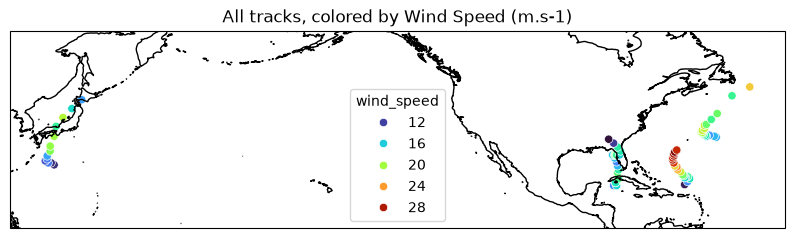

In [10]:
import huracanpy
import matplotlib.pyplot as plt

tracks = huracanpy.load("tctrack_outputs/tracks.nc", trajectory_id=["trajectory"])

intensity = tracks.wind_speed
_, ax = huracanpy.plot.tracks(tracks.lon, tracks.lat, intensity_var=intensity)

ax.set_ylim(10, 60)
plt.title(f"All tracks, colored by {intensity.long_name} ({intensity.units})")
plt.show()